# 1. Problem — five spatial angular-response fields from real polarization images


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`intensity`，shape `(1, 16, 2048, 2448)`，dtype `<f4`：Linear monochrome HDR intensity, in relative instrumental radiance units; axes batch, measured state, row, column. Values above one are valid.；`polarizer_psg`，shape `(1, 16)`，dtype `<f8`：Illumination-side polarizer angles g, in radians, matched to the intensity state axis.；`polarizer_psa`，shape `(1, 16)`，dtype `<f8`：Camera-side analyzer angles c, in radians, matched to the intensity state axis.。未知量为2048×2448每像素五个偏振角响应实场。

获取模型：16组generator/analyzer角度的sum/difference二阶谐波将5个未知光传输系数映射为HDR辐亮度。

如何恢复：src.solvers.reconstruct：5基底完整分辨率闭式最小二乘及复系数转换。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell6完整逆解；8原方法与Judge；9六图含16-state观测、五场、前向残差、9basis/control与加噪。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。角谐波不是唯一反射bounce次数或表面法线；无独立光路径真值。

<!-- inverse-evidence-audit:20261026:end -->


Rotating both illumination and analyzer polarizers reveals coupled light transport that an ordinary image cannot separate. This benchmark binds all16 native2048×2448 monochrome HDR frames of a real reflective scene. We recover five fields, retaining both complex harmonic coherences and a signed polarization-independent component. These are precisely defined angular responses, rather than a claim that each camera pixel has a uniquely known reflection-bounce path.

**Evidence classes.** “Original” means two actual full unchanged author runs on these exact measurements. “Fresh” means the local inverse actively executed below. There is no independently measured path-separated truth. Paper figures are historical context, not numeric measurements from this run. No precomputed reconstruction is substituted for the active inverse.

The selected paper is R.Maeda and S.Hiura, *Polarimetric Light Transport Analysis for Specular Inter-reflection*, IEEE TCI10,876–887(2024), DOI10.1109/TCI.2024.3404612. Actual archived arXiv2312.04140v2[15May2024] andv3[20Mar2026] were read. The paper's main-angle convention differs from its appendix/source; both algebra and local Jones-basis checks are documented in validation. Source F/R labels are mapped to sum/difference families without asserting unrecorded hardware handedness.

In [1]:
from pathlib import Path
import sys,time,json,hashlib,platform,subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
root=Path.cwd()
if not (root/'src').is_dir():root=root.parent
assert (root/'src').is_dir()
sys.path.insert(0,str(root))
from src.preprocessing import load_observations
from src.main import main
from src.physics_model import relative_residual
from src.solvers import review_comparisons
from src.visualization import make_figures
print({'actual_kernel_sys_executable':sys.executable,'python':platform.python_version(),'numpy':np.__version__,'mode':'Active complete reconstruction and newly computed scientific controls'})

{'actual_kernel_sys_executable': 'D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe', 'python': '3.11.11', 'numpy': '2.4.6', 'mode': 'Active complete reconstruction and newly computed scientific controls'}


# 2. Data — full real HDR observations and legitimate angle calibration

The sole solver input is numeric `data/raw_data.npz`: intensity(1,16,2048,2448)float32 and generator/analyzer angles(1,16)float64 radians. Four orientations0°,45°,90°,135° on each side form all16 combinations. Rows increase downward and columns rightward. Intensities use relative instrumental radiance units; no absolute radiometer or physical pixel pitch is invented. Values above1 remain valid; display tone mapping never enters inversion.

The public author data offer supports this local research package. No independent external redistribution license was identified, and source MIT/paper terms are not silently applied to the raw data. The source's lower clipping is retained; all original samples are already positive. No target-derived foreground support, normalization gain, cropped image, downsampled grid or hidden path label is used.

In [2]:
data=load_observations()
for key,a in data.items():print(key,a.shape,a.dtype)
print({'full_measured_pixel_values':int(data['intensity'].size),'raw_min':float(data['intensity'].min()),'raw_max':float(data['intensity'].max()),'negative_input_count':int(np.count_nonzero(data['intensity']<0))})
print('Recorded generator/analyzer angles (deg):')
print(np.column_stack([np.rad2deg(data['polarizer_psg']),np.rad2deg(data['polarizer_psa'])]))

intensity (16, 2048, 2448) float32
polarizer_psg (16,) float64
polarizer_psa (16,) float64
{'full_measured_pixel_values': 80216064, 'raw_min': 0.00046333164209499955, 'raw_max': 155.8404998779297, 'negative_input_count': 0}
Recorded generator/analyzer angles (deg):
[[  0.   0.]
 [  0.  45.]
 [  0.  90.]
 [  0. 135.]
 [ 45.   0.]
 [ 45.  45.]
 [ 45.  90.]
 [ 45. 135.]
 [ 90.   0.]
 [ 90.  45.]
 [ 90.  90.]
 [ 90. 135.]
 [135.   0.]
 [135.  45.]
 [135.  90.]
 [135. 135.]]


# 3. Physics — calibrated sum-angle and difference-angle harmonics

For pixel location r, recorded generator angle g and analyzer angle c, the selected restricted transport model is

$$I(r;g,c)=\frac{U+|C_s|+|C_d|}{2}+\frac12\operatorname{Re}\left[C_se^{-2i(c+g)}+C_de^{-2i(c-g)}\right].$$

U is the real polarization-independent component, Cs=sr+i si is the complex sum-angle field and Cd=dr+i di the difference-angle field, all in the same instrumental radiance units. Each complex argument is twice the polarization half-angle; storing Cartesian quadratures avoids arbitrary phase at a zero amplitude. All five real fields are required over the full camera image, with no fitted rotation or radiometric gain.

The model omits analyzer-only and generator-only modulation. Diattenuation, more complicated material polarization and acquisition noise can therefore produce structured residuals. A negative fitted U is retained and quantified rather than erased. The independent Jones tests verify mirror-parity angular responses within declared local bases, but metadata does not independently fix every mechanical viewing direction. Thus a harmonic family alone is not certified unique path truth.

# 4. Method — active full-resolution published closed-form inverse

Expanding the angular equation yields a linear coefficient vector x and row

$$W(g,c)=(1,\cos2c\cos2g,\sin2c\sin2g,\cos2c\sin2g,\sin2c\cos2g).$$

The method minimizes the unweighted sum of squared state residuals independently at every pixel. A full-rank pseudoinverse computes x=Wplus y, without iteration, initialization or spatial regularization. The actual16-state design has rank5 and condition2.

The native formulas give sr=x2−x3, si=x4+x5, dr=x2+x3, di=−x4+x5, and U=2x1−sqrt(sr²+si²)−sqrt(dr²+di²). Source amplitudes and half-angle phases are preserved by this invertible five-field representation. NumPy general SVD/pseudoinverse is a numerical primitive; all acquisition terms and component transformations are explicit local code.

The next cell executes the standard complete benchmark path. It reads only public observations/calibration and writes the declared submission. Hidden original references are loaded only afterward for maintainer evaluation.

In [3]:
start=time.perf_counter()
fresh=main()
primary_runtime=time.perf_counter()-start
print({'fresh_complete_standard_path_seconds':primary_runtime,'shape':fresh['reconstruction'].shape,'finite':bool(np.isfinite(fresh['reconstruction']).all())})

Complete16-state2048x2448 five-field reconstruction: 13.983492s
{'fresh_complete_standard_path_seconds': 14.003622899996117, 'shape': (5, 2048, 2448), 'finite': True}


# 5. Results — original parity, model discrepancy and genuinely computed controls

All five complete signed channels are compared against the independently executed original. Per-channel error is ||fresh−original||2/||original||2, without mean subtraction, crop, phase alignment, gain fitting or magnitude substitution. The observation metric is sqrt(sum(predicted−observed)²/sum(observed²)) across all16 full images. Nonzero1e−6 field tolerances were frozen from actual float32 round trips before local reconstruction. The original model residual is deliberately not claimed to be zero.

The active controls are: a nine-term linear Mueller response adding the four omitted single-polarizer terms; fixed angle-only5/8/12/16 measurement budgets; and three full-grid Gaussian perturbations at0.5%,1%,2% of each measured frame's spatial RMS. The added noise is a numerical sensitivity study, not an estimated instrument noise level. Native lower clipping is retained and its newly clipped fraction reported. Every displayed method is actually computed. The paper's additional spatial-pattern/3D reconstruction experiments require other acquisitions not present in this16-state binding; no absent comparison is filled with zeros.

In [4]:
with np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False) as z:original=z['reconstruction'][0]
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as z:upstream_summary={k:z[k] for k in z.files}
residual=relative_residual(fresh['reconstruction'],data['intensity'],data['polarizer_psg'],data['polarizer_psa'])
judge_command=[sys.executable,str(root/'evaluation/judge.py'),'--prediction',str(root/'output/reconstruction.npz'),'--report',str(root/'output/judge_report.json')]
judge=subprocess.run(judge_command,cwd=root,capture_output=True,text=True,shell=False)
assert judge.returncode==0,judge.stderr
judge_report=json.loads((root/'output/judge_report.json').read_text(encoding='utf-8'))
print('Fresh complete standalone Judge:',json.dumps(judge_report['metrics'],indent=2))
control_start=time.perf_counter()
comparisons=review_comparisons(data,fresh)
control_runtime=time.perf_counter()-control_start
print({'actually_computed_full_grid_controls_seconds':control_runtime,'selected5basis_residual':residual['relative_l2'],'fresh9basis_residual':comparisons['relative9']})

Fresh complete standalone Judge: {
  "unpolarized_relative_l2": 0.0,
  "sum_real_relative_l2": 7.312534432631017e-17,
  "sum_imaginary_relative_l2": 1.0288259780401708e-16,
  "difference_real_relative_l2": 6.88497955186371e-17,
  "difference_imaginary_relative_l2": 1.0244989591088844e-16,
  "observation_relative_l2": 0.1524369895304416
}


{'actually_computed_full_grid_controls_seconds': 28.946668099990347, 'selected5basis_residual': 0.15243698953044157, 'fresh9basis_residual': 0.02948077533200727}


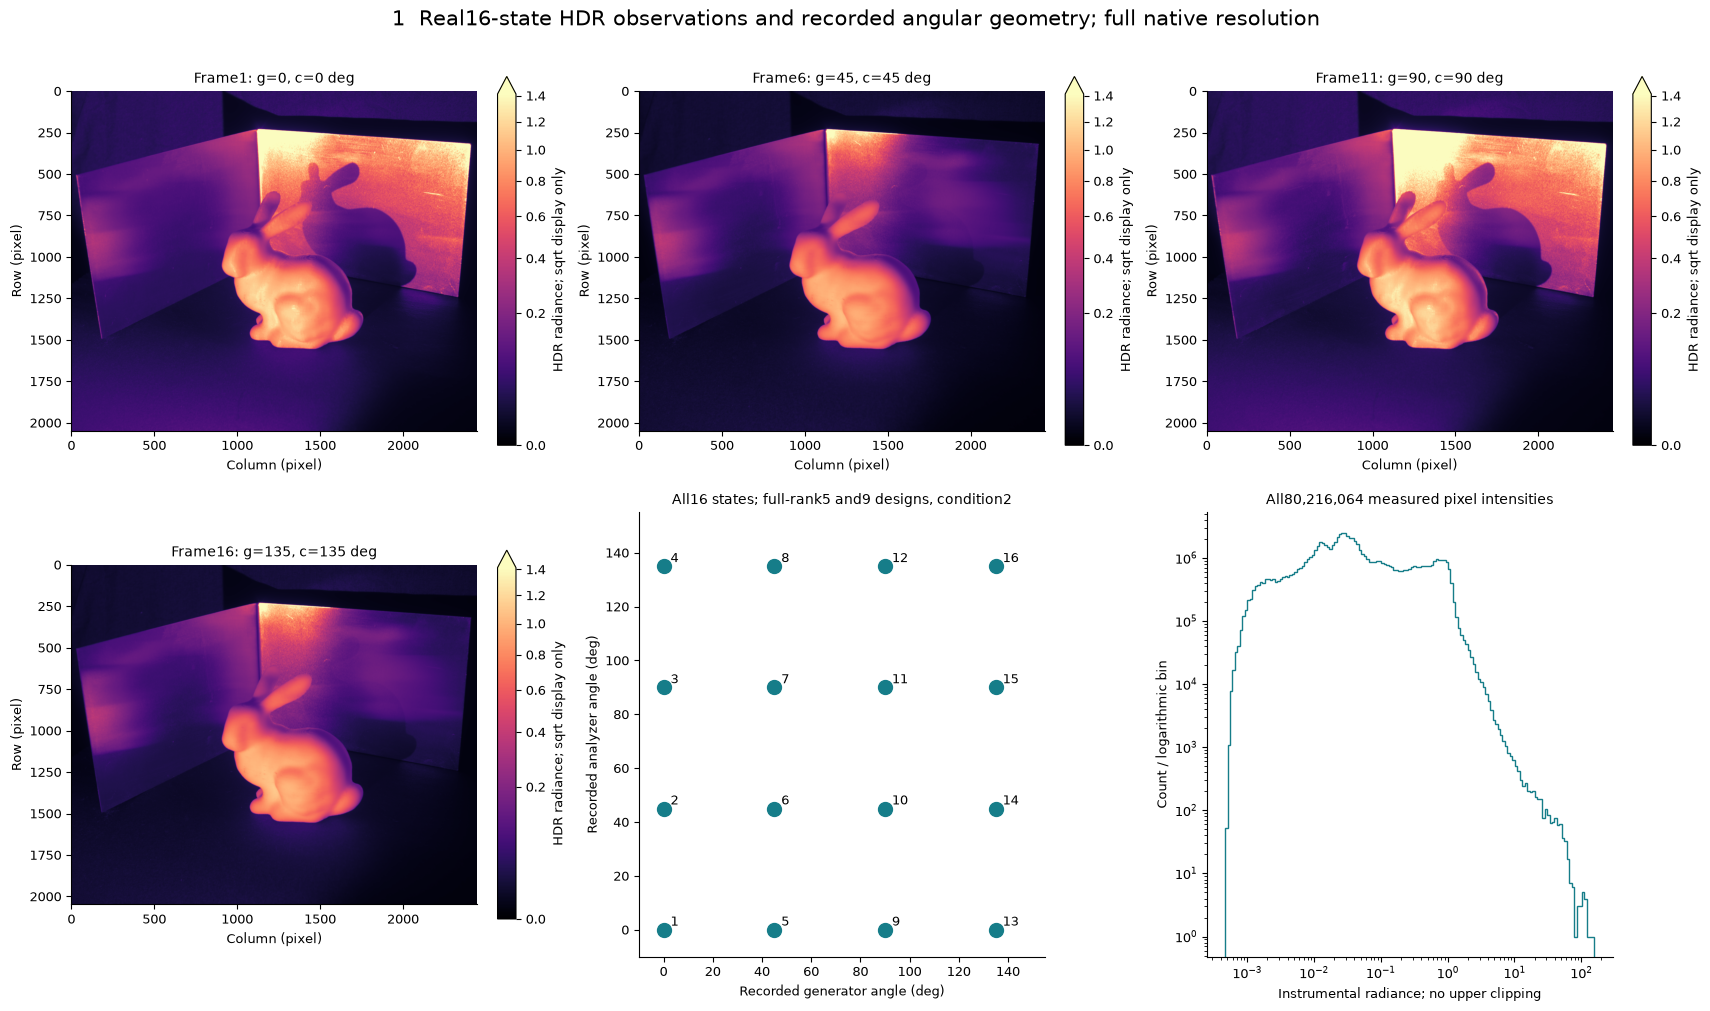

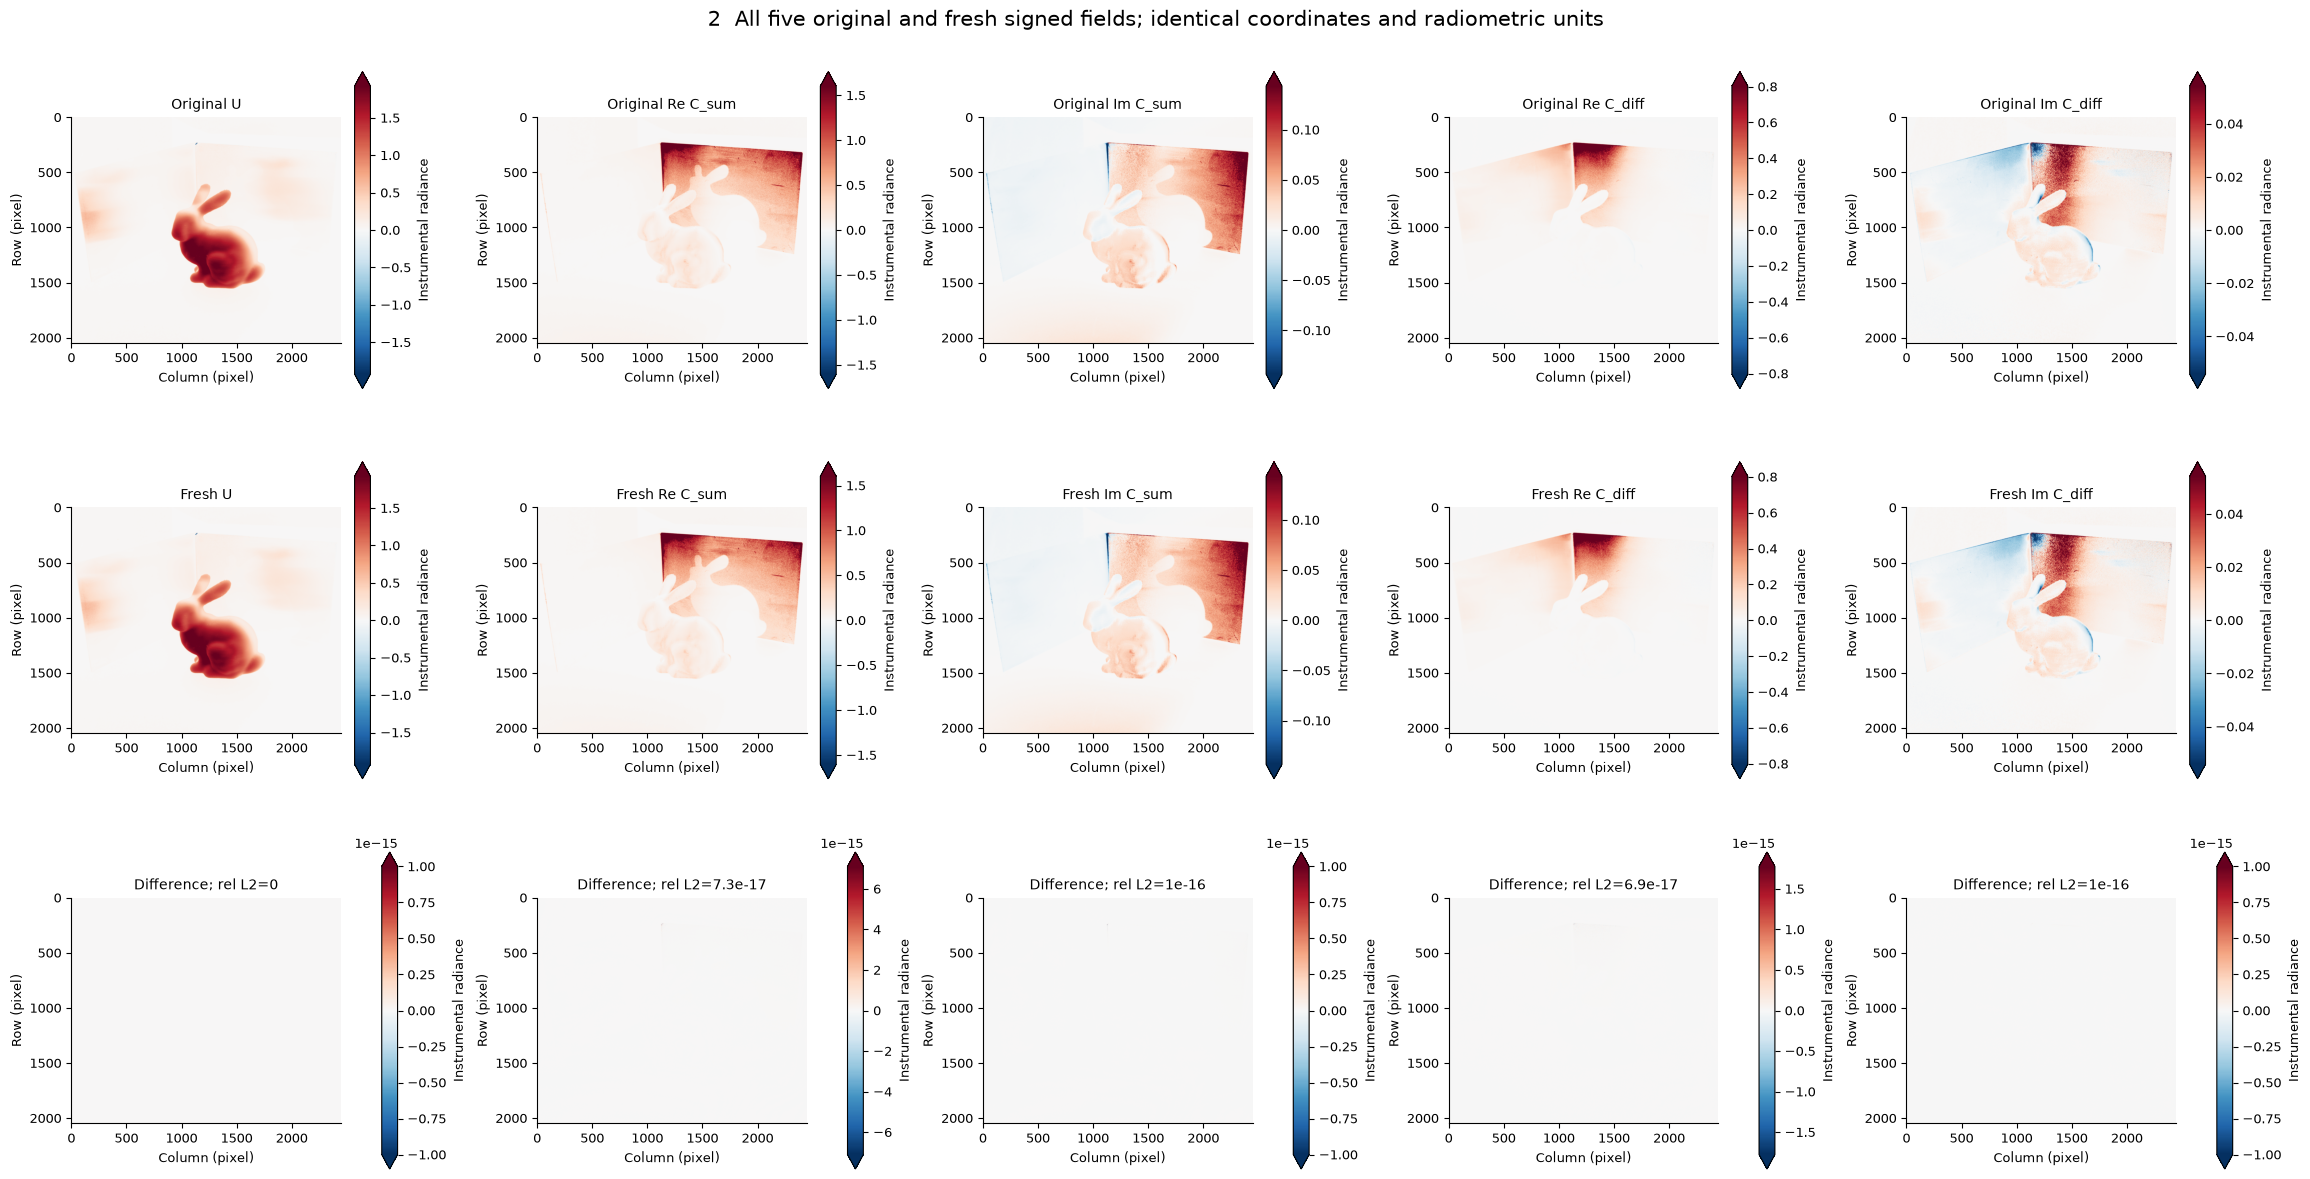

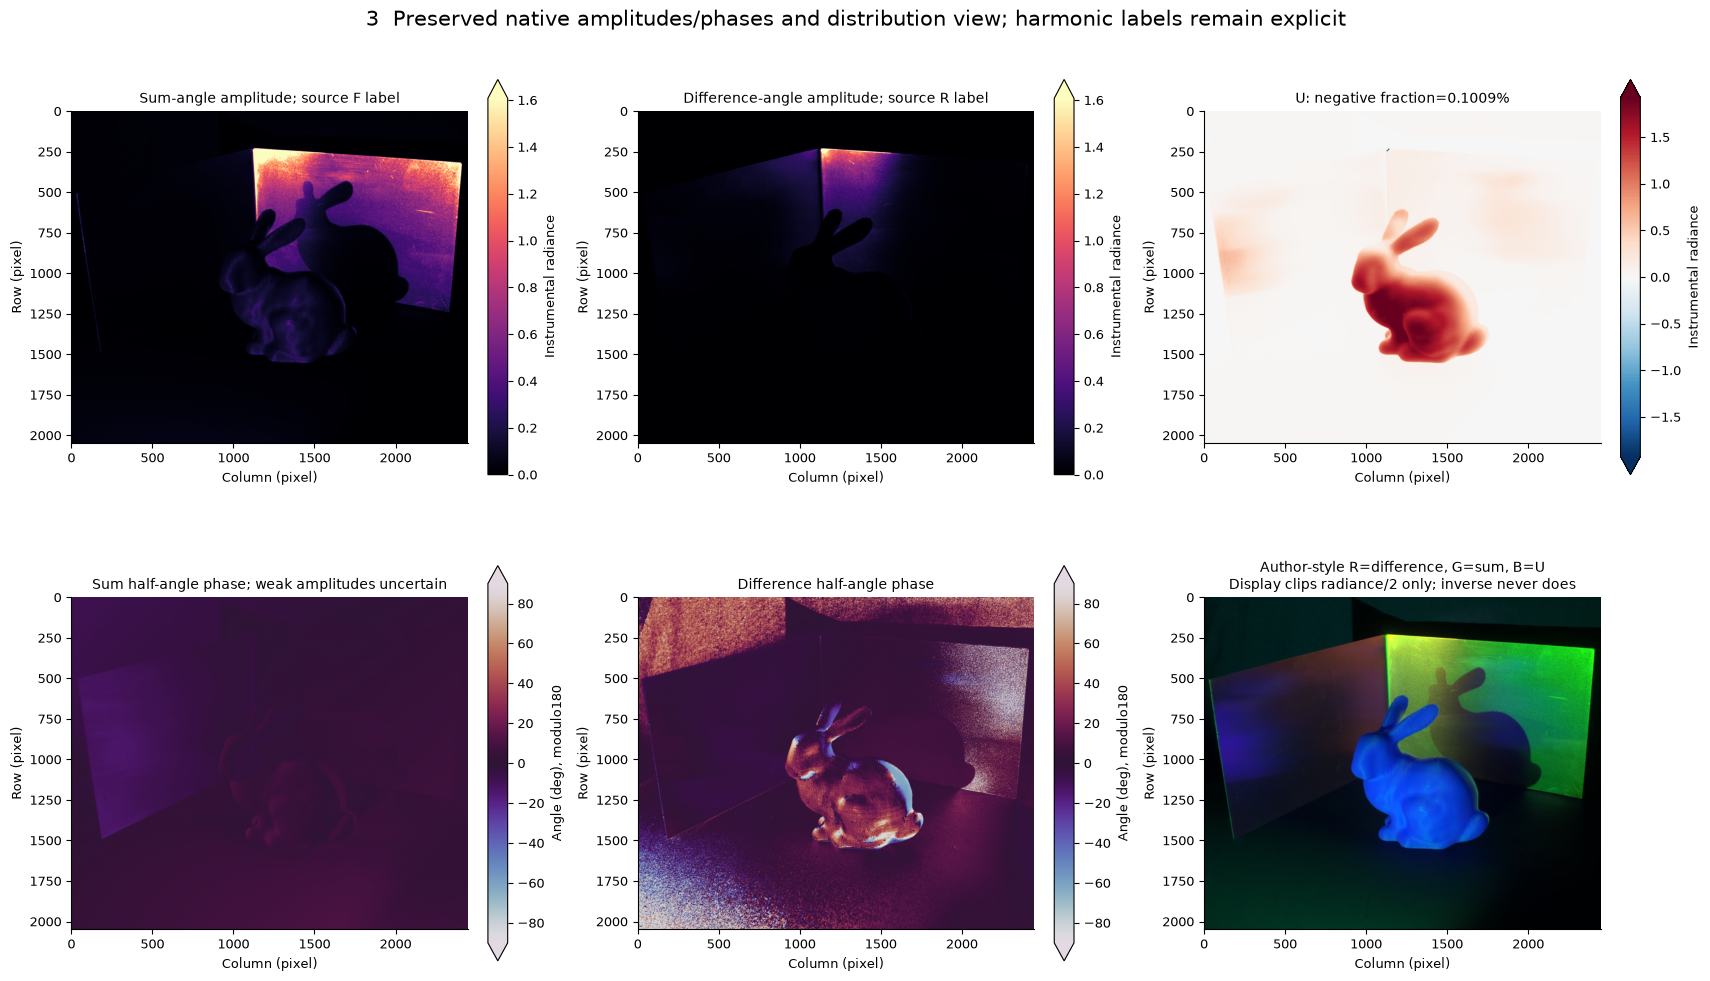

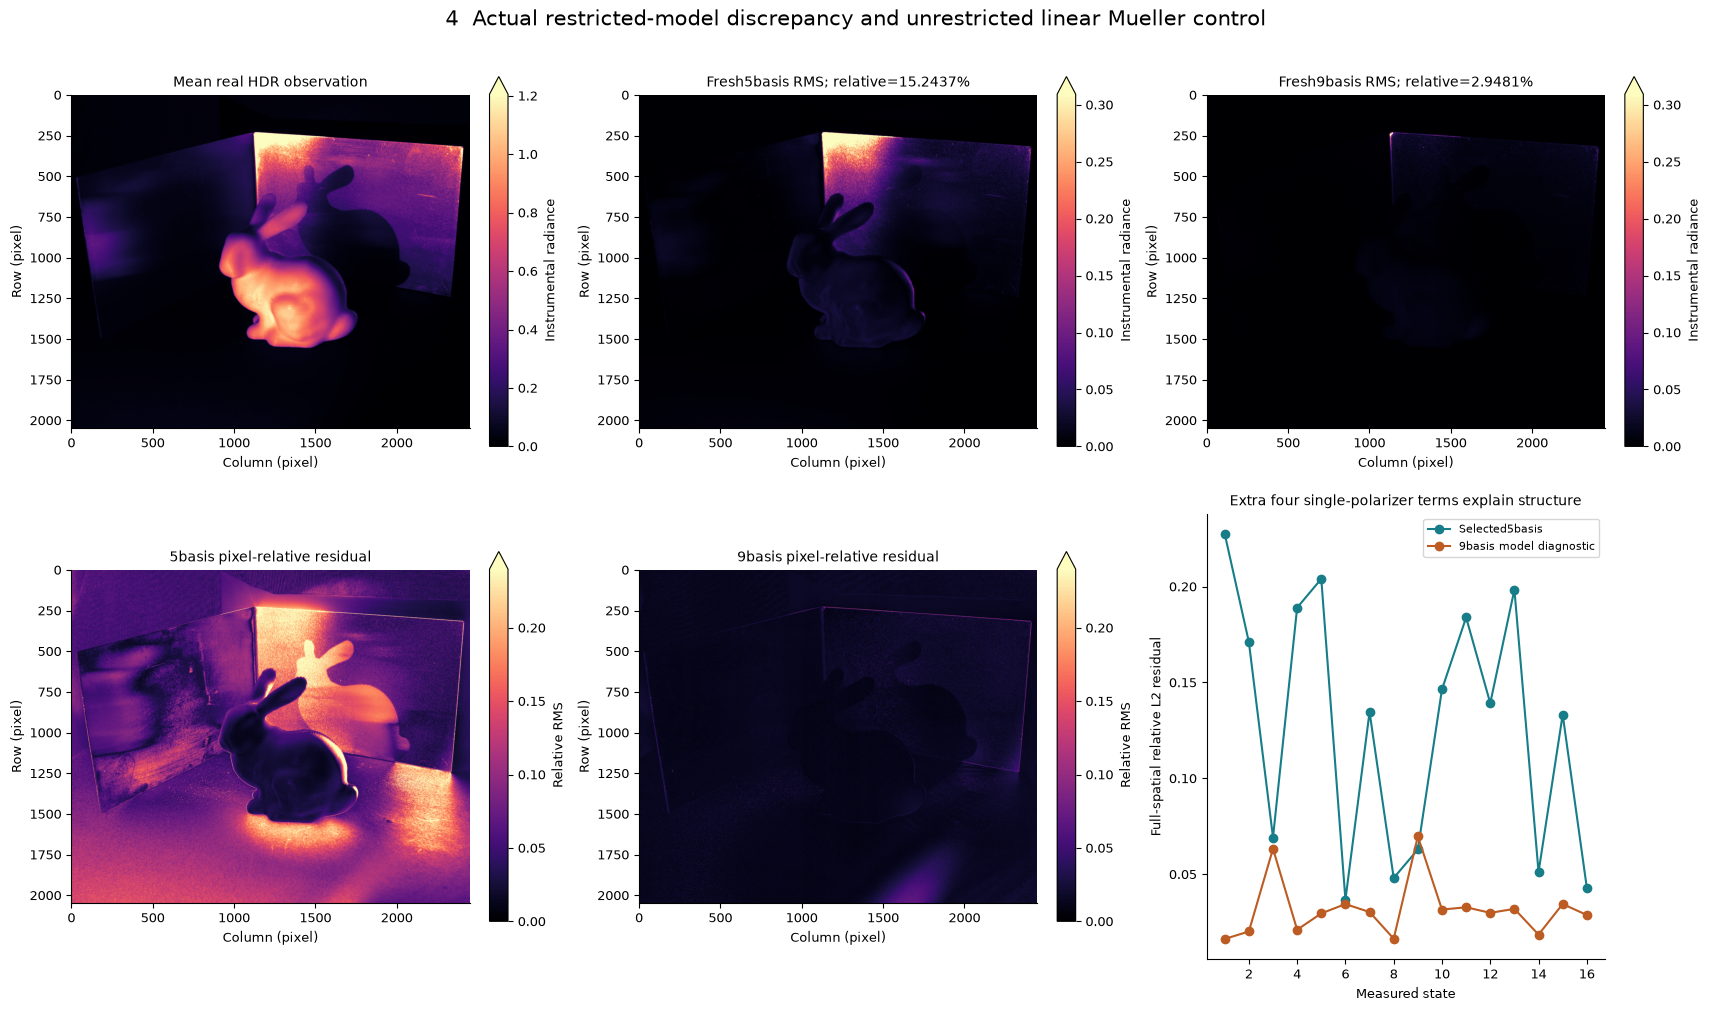

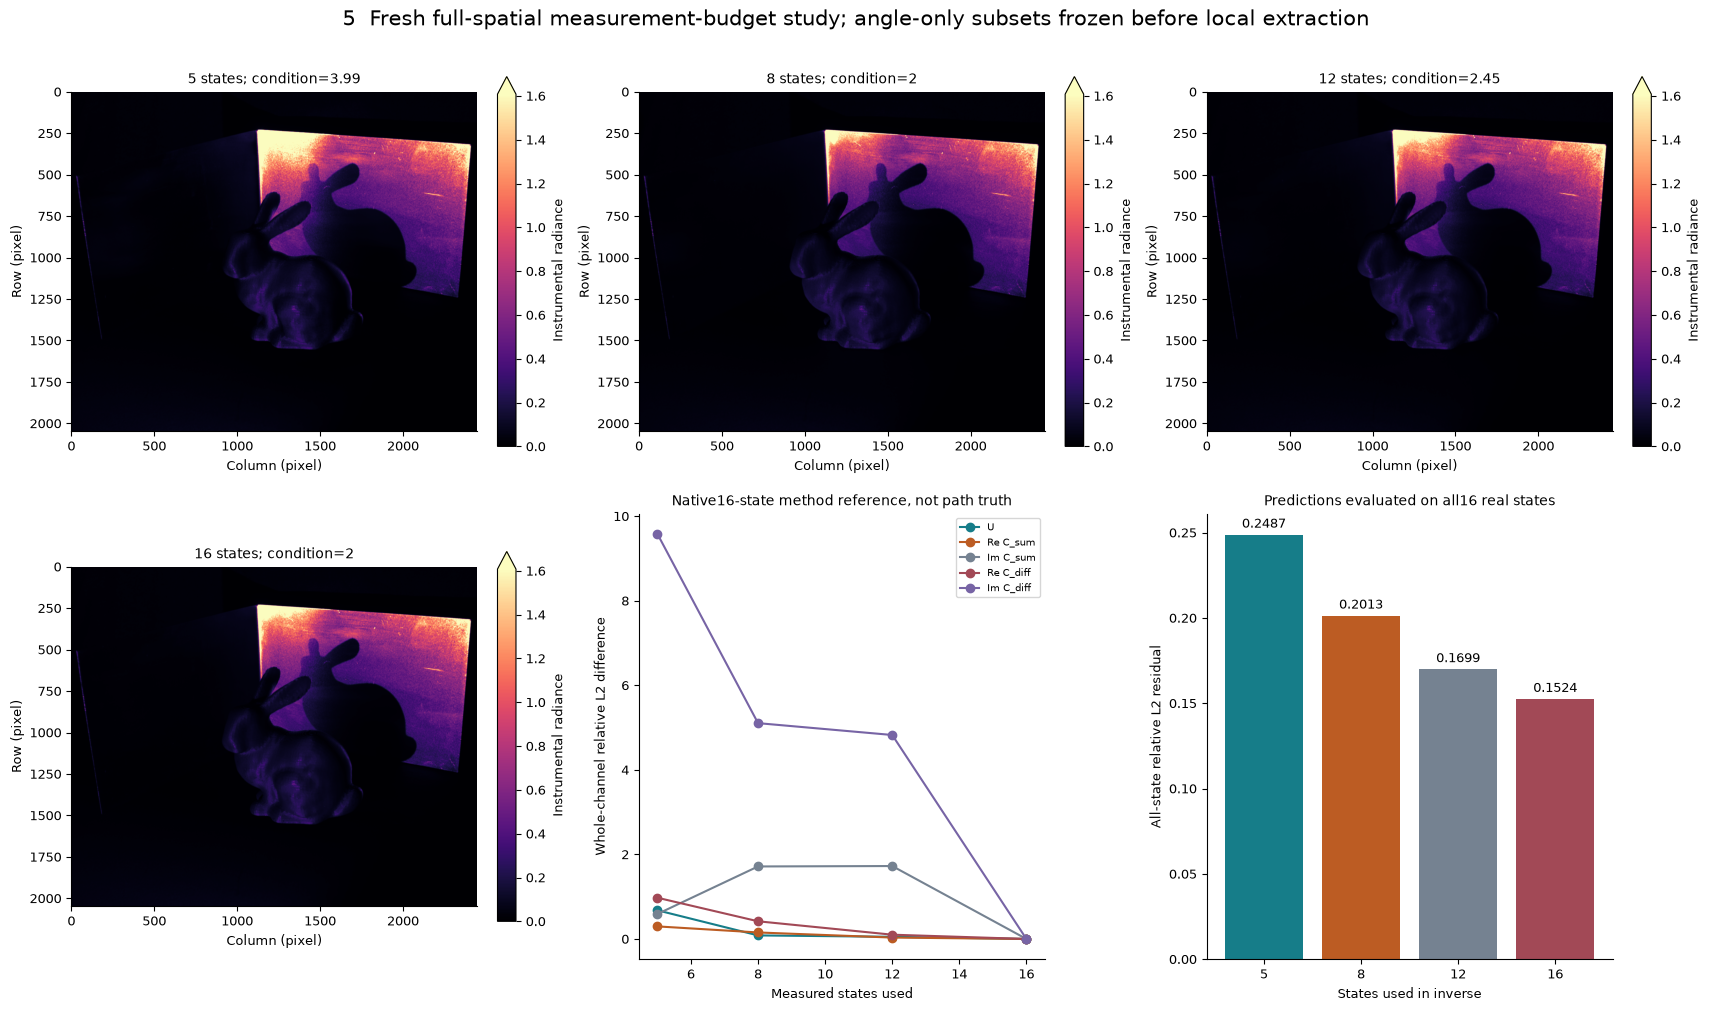

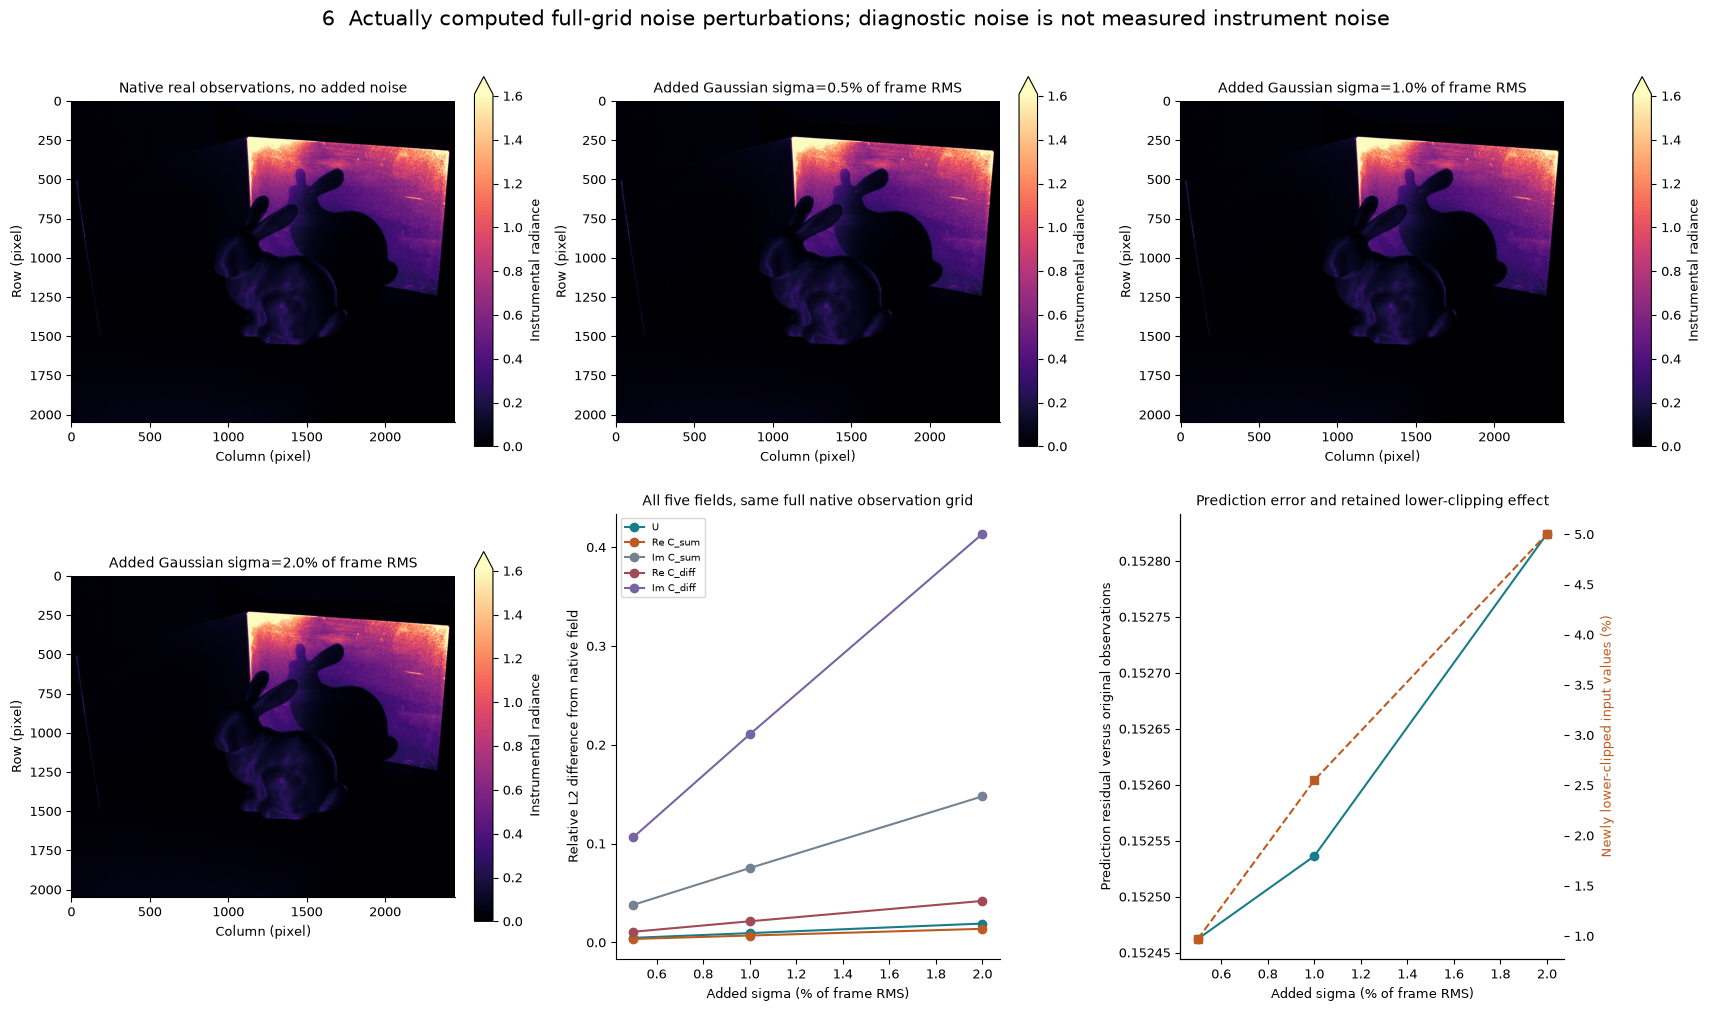

485

In [5]:
figure_directory=Path('D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research_batch7_20261022\\groups\\physics_materials\\polarimetric\\figures')
figures,measured=make_figures(data,original,fresh,residual,comparisons,upstream_summary,figure_directory)
for figure in figures:
    display(figure)
    plt.close(figure)
np.savez_compressed(root/'notebooks/reference_outputs/fresh_review.npz',channel_relative_l2=np.array(measured['full_original_fresh_channel_relative_l2']),fresh_forward_relative_l2=np.array(residual['relative_l2']),fresh_nine_basis_relative_l2=np.array(comparisons['relative9']),fresh_rms_map=residual['rms_map'],fresh_nine_rms_map=comparisons['rms9'])
execution={'actual_kernel_sys_executable':sys.executable,'primary_runtime_seconds':primary_runtime,'controls_runtime_seconds':control_runtime,'Judge_returncode':judge.returncode,'prediction_sha256':hashlib.sha256((root/'output/reconstruction.npz').read_bytes()).hexdigest(),'raw_sha256':hashlib.sha256((root/'data/raw_data.npz').read_bytes()).hexdigest(),'figures':6,'all_methods_actually_computed':True}
(figure_directory.parent/'notebook_measurements.json').write_text(json.dumps(execution,indent=2),encoding='utf-8')

# 6. Conclusion — numerical reproduction with an explicit physical-model limitation

The full-field inverse retains all five original degrees of freedom and agrees with the unchanged original within the independently frozen precision criteria. That agreement validates the extraction and selected numerical method; it does not create a measured path-separated truth.

The restricted five-basis model has a substantial structured observation residual. The independently derived nine-term control explains much of this structure through four additional angular terms. All states and pixels remain visible in both measurements. This comparison limits the interpretation of the fitted source F/R components, without changing the requested method or hiding troublesome regions.

The measurement-budget and noise studies quantify actual changes in every signed field. Reduced-angle results are compared to the native method reference, not called truth errors. Only display panels use tone mapping or saturation indicators; inverse arrays, residuals, numerical tables and the Judge preserve the full radiometric scale. No error bars or unique bounce-path accuracy are invented.

In [6]:
print(json.dumps({'original_fresh_channel_relative_l2':measured['full_original_fresh_channel_relative_l2'],'full5basis_relative_residual':measured['fresh_observation_relative_l2'],'full9basis_relative_residual':measured['fresh_unrestricted_nine_basis_relative_l2'],'signed_U_negative_fraction':measured['negative_unpolarized_fraction'],'signed_U_minimum':measured['minimum_unpolarized'],'Judge_passed':judge_report['passed'],'primary_runtime_seconds':primary_runtime,'controls_runtime_seconds':control_runtime},indent=2))

{
  "original_fresh_channel_relative_l2": [
    0.0,
    7.312534432631017e-17,
    1.0288259780401708e-16,
    6.88497955186371e-17,
    1.0244989591088844e-16
  ],
  "full5basis_relative_residual": 0.15243698953044157,
  "full9basis_relative_residual": 0.02948077533200727,
  "signed_U_negative_fraction": 0.0010088752297794119,
  "signed_U_minimum": -17.160151989388282,
  "Judge_passed": true,
  "primary_runtime_seconds": 14.003622899996117,
  "controls_runtime_seconds": 28.946668099990347
}
